REPRODUCING PAPER EXAMPLE 1 (Section 3.2)

--- Calculations ---
D1 Calculated Result: {'1': 1.0000000000000002, '2': 1.0000000000000002, '3': 1.0000000000000002, '4': 1.0000000000000002, '5': 1.0000000000000002}
D2 Calculated Result: {'1': 5.0, '2': 5.0, '3': 5.0, '4': 5.0, '5': 5.0}
D3 Calculated Result (from diagram): {'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0000000000000002}
D3 Paper's Stated Result (from text): {'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0}

✓ Saved visualization to 'paper_digraphs_visualization.png'


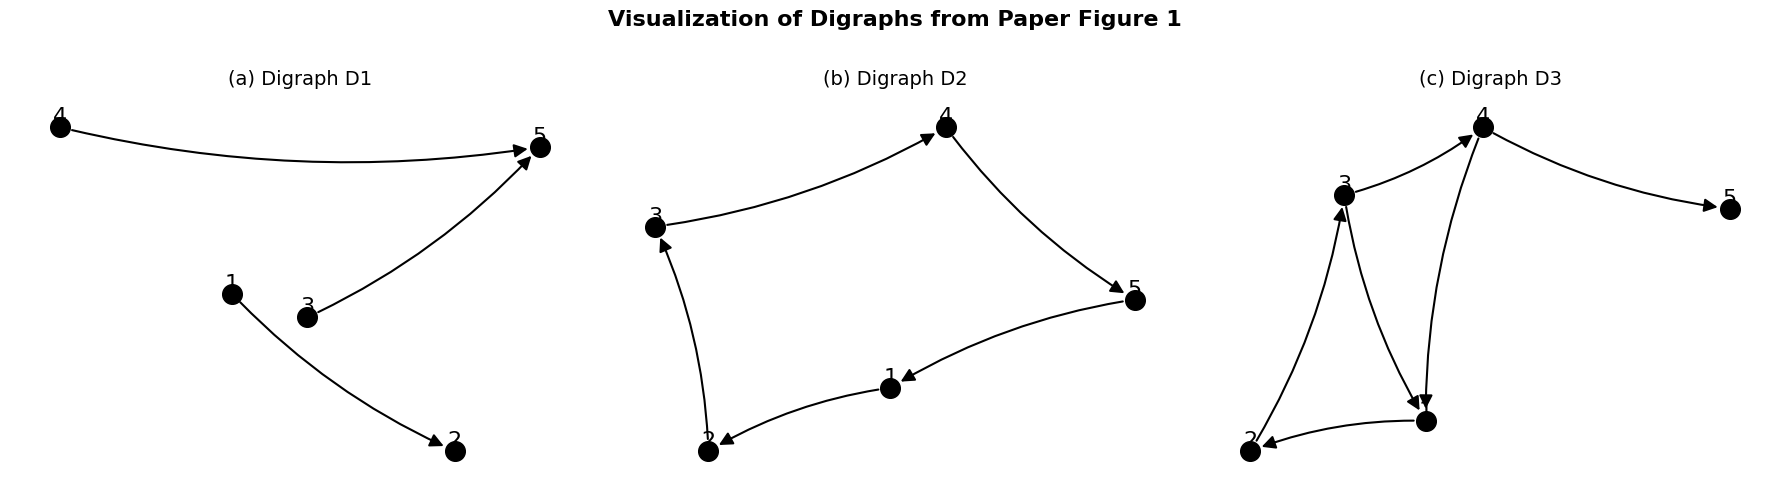

In [18]:
import numpy as np
import pandas as pd
import networkx as nx
import math
import matplotlib.pyplot as plt
from itertools import combinations
from typing import Dict, Set, FrozenSet, List, Callable
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

class TUGame:
    def __init__(self, players: List[str], v_func: Callable[[FrozenSet[str]], float]):
        self.players = players; self.N = frozenset(players); self.v = v_func
    def worth(self, S: Set[str]) -> float:
        return 0.0 if not S else self.v(frozenset(S))
    def shapley_value(self) -> Dict[str, float]:
        n = len(self.players); phi = {p: 0.0 for p in self.players}
        for player in self.players:
            others = [p for p in self.players if p != player]
            for r in range(n):
                for S_tuple in combinations(others, r):
                    S = set(S_tuple)
                    weight = (math.factorial(r) * math.factorial(n - r - 1)) / math.factorial(n)
                    marginal = self.worth(S | {player}) - self.worth(S)
                    phi[player] += weight * marginal
        return phi

class DigraphGame(TUGame):
    def __init__(self, players: List[str], v_func: Callable[[FrozenSet[str]], float], digraph: nx.DiGraph):
        super().__init__(players, v_func); self.D = digraph
    def v_restricted(self, S: Set[str]) -> float:
        if not S: return 0.0
        subgraph = self.D.subgraph(S)
        sccs = nx.strongly_connected_components(subgraph)
        return sum(self.worth(set(scc)) for scc in sccs)
    def myerson_value(self) -> Dict[str, float]:
        restricted_game = TUGame(self.players, lambda s: self.v_restricted(set(s)))
        return restricted_game.shapley_value()

def reproduce_paper_example():
    """
    Reproduces Example 1 using the EXACT graphs from the paper's Figure 1 and visualizes them.
    """
    print("="*70 + "\nREPRODUCING PAPER EXAMPLE 1 (Section 3.2)\n" + "="*70)
    players = ['1', '2', '3', '4', '5']
    def v_quadratic(S: FrozenSet[str]) -> float: return len(S) ** 2

    # Graph D1: Exact edges from Figure 1(a)
    D1 = nx.DiGraph(); D1.add_nodes_from(players)
    D1.add_edges_from([('1', '2'), ('3', '5'), ('4', '5')])

    # Graph D2: Exact edges from Figure 1(b)
    D2 = nx.DiGraph(); D2.add_nodes_from(players)
    D2.add_edges_from([('1', '2'), ('2', '3'), ('3', '4'), ('4', '5'), ('5', '1')])

    # Graph D3: Exact edges from Figure 1(c)
    D3 = nx.DiGraph(); D3.add_nodes_from(players)
    D3.add_edges_from([('1', '2'), ('3', '1'), ('2', '3'), ('3', '4'),('4','1'), ('4', '5')])

    graphs = {'(a) Digraph D1': D1, '(b) Digraph D2': D2, '(c) Digraph D3': D3}

    print("\n--- Calculations ---")
    game1 = DigraphGame(players, v_quadratic, D1); mu1 = game1.myerson_value()
    game2 = DigraphGame(players, v_quadratic, D2); mu2 = game2.myerson_value()
    game3 = DigraphGame(players, v_quadratic, D3); mu3 = game3.myerson_value()

    print(f"D1 Calculated Result: {mu1}")
    print(f"D2 Calculated Result: {mu2}")
    print(f"D3 Calculated Result (from diagram): {mu3}")
    print(f"D3 Paper's Stated Result (from text): {{'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0}}")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Visualization of Digraphs from Paper Figure 1', fontsize=16, fontweight='bold')

    for ax, (title, G) in zip(axes, graphs.items()):
        pos = nx.spring_layout(G, seed=42, k=0.9)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color='black', node_size=200)
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color='black', arrowsize=20, width=1.5,
                               connectionstyle='arc3,rad=0.1')
        nx.draw_networkx_labels(G, pos, ax=ax, font_color='black', font_size=16, verticalalignment='bottom')
        ax.set_title(title, fontsize=14)
        ax.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig('paper_digraphs_visualization.png')
    print("\nSaved visualization to 'paper_digraphs_visualization.png'")

def main():
    reproduce_paper_example()

if __name__ == "__main__":
    main()

REPRODUCING PAPER EXAMPLE 1 (Section 3.2)

--- Calculations ---
D1 Calculated Result: {'1': 1.0000000000000002, '2': 1.0000000000000002, '3': 1.0000000000000002, '4': 1.0000000000000002, '5': 1.0000000000000002}
D2 Calculated Result: {'1': 5.0, '2': 5.0, '3': 5.0, '4': 5.0, '5': 5.0}
D3 Calculated Result (from diagram): {'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0000000000000002}
D3 Paper's Stated Result (from text): {'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0}

✓ Saved visualization to 'paper_digraphs_visualization.png'

DATASET: cv_risk
Features: ['diet_score', 'sleep_duration', 'family_history', 'bmi']
Graph | nodes=4, edges=2 (corr>|0.25|)
SCCs: 4 | sizes (desc): [1, 1, 1, 1]

Top features by Myerson value:
                Myerson_Value  Shapley_Value  Difference
Feature                                                 
bmi                    0.5479         0.5133      0.0347
diet_score             0.0000         0.0633     -0.0633
sleep_duration         0.0000         0.

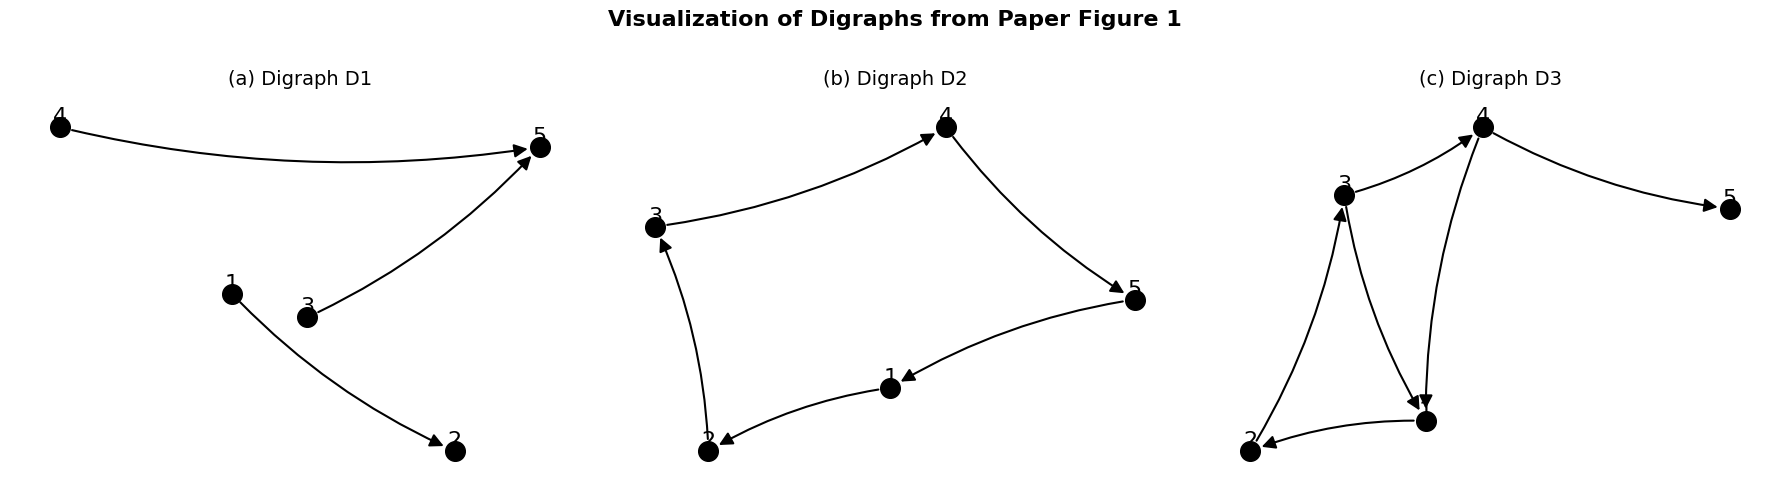

<Figure size 800x450 with 0 Axes>

<Figure size 800x450 with 0 Axes>

In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
import math
import matplotlib.pyplot as plt
from itertools import combinations
from typing import Dict, Set, FrozenSet, List, Callable
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

class TUGame:
    def __init__(self, players: List[str], v_func: Callable[[FrozenSet[str]], float]):
        self.players = players; self.N = frozenset(players); self.v = v_func
    def worth(self, S: Set[str]) -> float:
        return 0.0 if not S else self.v(frozenset(S))
    def shapley_value(self) -> Dict[str, float]:
        n = len(self.players); phi = {p: 0.0 for p in self.players}
        for player in self.players:
            others = [p for p in self.players if p != player]
            for r in range(n):
                for S_tuple in combinations(others, r):
                    S = set(S_tuple)
                    weight = (math.factorial(r) * math.factorial(n - r - 1)) / math.factorial(n)
                    marginal = self.worth(S | {player}) - self.worth(S)
                    phi[player] += weight * marginal
        return phi

class DigraphGame(TUGame):
    def __init__(self, players: List[str], v_func: Callable[[FrozenSet[str]], float], digraph: nx.DiGraph):
        super().__init__(players, v_func); self.D = digraph
    def v_restricted(self, S: Set[str]) -> float:
        if not S: return 0.0
        subgraph = self.D.subgraph(S)
        sccs = nx.strongly_connected_components(subgraph)
        return sum(self.worth(set(scc)) for scc in sccs)
    def myerson_value(self) -> Dict[str, float]:
        restricted_game = TUGame(self.players, lambda s: self.v_restricted(set(s)))
        return restricted_game.shapley_value()

def reproduce_paper_example():
    """
    Reproduces Example 1 using the EXACT graphs from the paper's Figure 1 and visualizes them.
    """
    print("="*70 + "\nREPRODUCING PAPER EXAMPLE 1 (Section 3.2)\n" + "="*70)
    players = ['1', '2', '3', '4', '5']
    def v_quadratic(S: FrozenSet[str]) -> float: return len(S) ** 2

    # Graph D1: Exact edges from Figure 1(a)
    D1 = nx.DiGraph(); D1.add_nodes_from(players)
    D1.add_edges_from([('1', '2'), ('3', '5'), ('4', '5')])

    # Graph D2: Exact edges from Figure 1(b)
    D2 = nx.DiGraph(); D2.add_nodes_from(players)
    D2.add_edges_from([('1', '2'), ('2', '3'), ('3', '4'), ('4', '5'), ('5', '1')])

    # Graph D3: Exact edges from Figure 1(c)
    D3 = nx.DiGraph(); D3.add_nodes_from(players)
    D3.add_edges_from([('1', '2'), ('3', '1'), ('2', '3'), ('3', '4'),('4','1'), ('4', '5')])

    graphs = {'(a) Digraph D1': D1, '(b) Digraph D2': D2, '(c) Digraph D3': D3}

    print("\n--- Calculations ---")
    game1 = DigraphGame(players, v_quadratic, D1); mu1 = game1.myerson_value()
    game2 = DigraphGame(players, v_quadratic, D2); mu2 = game2.myerson_value()
    game3 = DigraphGame(players, v_quadratic, D3); mu3 = game3.myerson_value()

    print(f"D1 Calculated Result: {mu1}")
    print(f"D2 Calculated Result: {mu2}")
    print(f"D3 Calculated Result (from diagram): {mu3}")
    print(f"D3 Paper's Stated Result (from text): {{'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0}}")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Visualization of Digraphs from Paper Figure 1', fontsize=16, fontweight='bold')

    for ax, (title, G) in zip(axes, graphs.items()):
        pos = nx.spring_layout(G, seed=42, k=0.9)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color='black', node_size=200)
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color='black', arrowsize=20, width=1.5,
                               connectionstyle='arc3,rad=0.1')
        nx.draw_networkx_labels(G, pos, ax=ax, font_color='black', font_size=16, verticalalignment='bottom')
        ax.set_title(title, fontsize=14)
        ax.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig('paper_digraphs_visualization.png')
    print("\nSaved visualization to 'paper_digraphs_visualization.png'")


from sklearn.model_selection import KFold

def create_interactional_v_func(X: pd.DataFrame, y: np.ndarray, model_template, k: int = 3):
    memo = {}
    X_vals = X.values
    cols = list(X.columns)
    k = max(2, min(k, len(y)))  # guard

    def v(S: FrozenSet[str]) -> float:
        if not S: return 0.0
        if S in memo: return memo[S]
        idx = [cols.index(c) for c in S]
        X_sub = X_vals[:, idx]
        kf = KFold(n_splits=k, shuffle=True, random_state=42)
        scores = []
        for tr, te in kf.split(X_sub):
            m = clone(model_template)
            m.fit(X_sub[tr], y[tr])
            yhat = m.predict(X_sub[te])
            scores.append(r2_score(y[te], yhat))
        score = max(0.0, float(np.mean(scores)))  # worth must be ≥ 0
        memo[S] = score
        return score
    return v

def build_digraph_from_correlations(X: pd.DataFrame, threshold: float = 0.25, eps_var: float = 1e-9) -> nx.DiGraph:
    corr = X.corr().abs()
    var = X.var()
    keep = [c for c in X.columns if var[c] > eps_var]
    D = nx.DiGraph(); D.add_nodes_from(keep)
    for i in keep:
        for j in keep:
            if i >= j:  # skip self/dups
                continue
            if corr.loc[i, j] > threshold:
                if var[i] > var[j]:
                    D.add_edge(i, j)
                elif var[j] > var[i]:
                    D.add_edge(j, i)
                else:
                    a, b = sorted([i, j])
                    D.add_edge(a, b)
    return D

def print_scc_summary(D: nx.DiGraph):
    sccs = list(nx.strongly_connected_components(D))
    sizes = sorted([len(s) for s in sccs], reverse=True)
    print(f"SCCs: {len(sccs)} | sizes (desc): {sizes}")

def shapley_permutation_sampling(players: List[str], worth_fn: Callable[[FrozenSet[str]], float], m: int = 2048, seed: int = 42) -> Dict[str, float]:
    rng = np.random.default_rng(seed)
    n = len(players)
    phi = {p: 0.0 for p in players}
    players_arr = np.array(players)
    for _ in range(m):
        perm = players_arr[rng.permutation(n)]
        S = frozenset()
        prev_val = worth_fn(S)
        for p in perm:
            S_new = frozenset(set(S) | {p})
            val_new = worth_fn(S_new)
            phi[p] += (val_new - prev_val)
            S, prev_val = S_new, val_new
    for p in phi:
        phi[p] /= m
    return phi

def compute_values(players: List[str],
                   v_func: Callable[[FrozenSet[str]], float],
                   D: nx.DiGraph,
                   max_exact_features: int = 12,
                   m_permutations: int = 4096) -> (Dict[str, float], Dict[str, float]):
    """
    Returns (myerson, shapley). Uses exact Shapley if feasible, else MC permutations.
    """
    n = len(players)
    # base and restricted worth functions (as frozensets)
    base_worth = lambda S: v_func(S)

    temp_game = DigraphGame(players, v_func, D)
    restricted_worth = lambda S: temp_game.v_restricted(set(S))

    if n <= max_exact_features:
        # exact
        base_game = TUGame(players, v_func)
        myerson = TUGame(players, restricted_worth).shapley_value()
        shapley = base_game.shapley_value()
    else:
        # MC permutations
        myerson = shapley_permutation_sampling(players, restricted_worth, m=m_permutations, seed=42)
        shapley = shapley_permutation_sampling(players, base_worth, m=m_permutations, seed=43)
    return myerson, shapley

def analyze_dataset(csv_path: str, dataset_name: str, target_hint: str = None,
                    corr_threshold: float = 0.25,
                    n_estimators: int = 120, max_depth: int | None = None,
                    cv_k: int = 3, m_permutations: int = 4096):
    print("\n" + "="*78)
    print(f"DATASET: {dataset_name}")
    print("="*78)

    df = pd.read_csv(csv_path)
    # drop unnamed
    df = df[[c for c in df.columns if not c.lower().startswith('unnamed')]]

    # target detection
    if target_hint and target_hint in df.columns:
        target_col = target_hint
    else:
        target_col = df.columns[-1]
    y = pd.to_numeric(df[target_col], errors='coerce')
    y = y.fillna(y.median())
    X = df.drop(columns=[target_col])

    # numeric features only
    X = X.select_dtypes(include=[np.number])
    if X.shape[1] == 0:
        raise ValueError("No numeric features found after dropping target.")
    X = X.fillna(X.median(numeric_only=True))

    scaler = StandardScaler()
    Xs = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

    rf_template = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, random_state=42, n_jobs=-1)
    v_func = create_interactional_v_func(Xs, y.values, rf_template, k=cv_k)

    D = build_digraph_from_correlations(Xs, threshold=corr_threshold)
    print(f"Features: {list(Xs.columns)}")
    print(f"Graph | nodes={len(D.nodes)}, edges={len(D.edges)} (corr>|{corr_threshold}|)")
    print_scc_summary(D)

    players = list(Xs.columns)
    myerson, shapley = compute_values(players, v_func, D,
                                      max_exact_features=12,
                                      m_permutations=m_permutations)

    res = pd.DataFrame({
        'Feature': players,
        'Myerson_Value': [myerson[p] for p in players],
        'Shapley_Value': [shapley[p] for p in players],
    }).set_index('Feature')
    res['Difference'] = res['Myerson_Value'] - res['Shapley_Value']
    res = res.sort_values('Myerson_Value', ascending=False)

    print("\nTop features by Myerson value:")
    print(res.head(15).to_string(float_format=lambda x: f"{x:0.4f}"))

    out_csv = f"myerson_results_{dataset_name}.csv"
    res.to_csv(out_csv)
    print(f"\nSaved results to {out_csv}")

    plt.figure(figsize=(max(8, 0.5*len(res)), 4.5))
    res[['Myerson_Value','Shapley_Value']].plot(kind='bar')
    plt.title(f"Myerson vs Shapley — {dataset_name}")
    plt.xlabel("Feature")
    plt.ylabel("Value")
    plt.tight_layout()
    out_png = f"myerson_vs_shapley_{dataset_name}.png"
    plt.savefig(out_png, dpi=180)
    plt.close()
    print(f"Saved plot to {out_png}")

def run_real_datasets():
    # cv_risk
    try:
        analyze_dataset("cv_risk.csv", "cv_risk", target_hint="cv_risk",
                        corr_threshold=0.25, n_estimators=120, max_depth=None, cv_k=3, m_permutations=4096)
    except FileNotFoundError:
        print("Warning: Skipping cv_risk: file not found at /mnt/data/cv_risk.csv")

    # lung_cancer_risk
    try:
        analyze_dataset("lung_cancer_risk.csv", "lung_cancer_risk", target_hint="lung_cancer_risk",
                        corr_threshold=0.25, n_estimators=120, max_depth=None, cv_k=3, m_permutations=4096)
    except FileNotFoundError:
        print("Warning: Skipping lung_cancer_risk: file not found at /mnt/data/lung_cancer_risk.csv")


def main():
    reproduce_paper_example()
    run_real_datasets()

if __name__ == "__main__":
    main()

In [24]:
# Myerson Value for Directed Graph Games - Paper Example + Real Data
# - Exact Shapley for small n; permutation fallback for larger n
# - Coalition worth v(S): RandomForest R^2 via k-fold CV (non-additive)
# - Correlation->digraph with stable direction & SCC summary
# - Memoization for big speed wins
import math
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from typing import Dict, Set, FrozenSet, List, Callable
from functools import lru_cache
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold

class TUGame:
    def __init__(self, players: List[str], v_func: Callable[[FrozenSet[str]], float]):
        self.players = players
        self.N = frozenset(players)
        self._v = v_func

    @lru_cache(maxsize=None)
    def worth_frozen(self, S: FrozenSet[str]) -> float:
        return 0.0 if not S else self._v(S)

    def worth(self, S: Set[str]) -> float:
        return self.worth_frozen(frozenset(S))

    def shapley_value(self) -> Dict[str, float]:
        n = len(self.players)
        phi = {p: 0.0 for p in self.players}
        # precompute factorials 0..n-1; use math.factorial(n) for denom
        fact = [math.factorial(i) for i in range(n)]
        denom = math.factorial(n)

        for player in self.players:
            others = [p for p in self.players if p != player]
            for r in range(n):
                w = (fact[r] * fact[n - r - 1]) / denom
                for S_tuple in combinations(others, r):
                    S = set(S_tuple)
                    phi[player] += w * (self.worth(S | {player}) - self.worth(S))
        return phi


class DigraphGame(TUGame):
    def __init__(self, players: List[str], v_func: Callable[[FrozenSet[str]], float], digraph: nx.DiGraph):
        super().__init__(players, v_func)
        self.D = digraph

    @lru_cache(maxsize=None)
    def v_restricted_frozen(self, S: FrozenSet[str]) -> float:
        if not S: return 0.0
        subgraph = self.D.subgraph(S)
        # sum of base worth over SCCs, per Myerson (Li & Shan, 2020)
        return sum(self.worth_frozen(frozenset(scc)) for scc in nx.strongly_connected_components(subgraph))

    def v_restricted(self, S: Set[str]) -> float:
        return self.v_restricted_frozen(frozenset(S))

    def myerson_value(self) -> Dict[str, float]:
        restricted = lambda s: self.v_restricted_frozen(frozenset(s))
        return TUGame(self.players, restricted).shapley_value()

def print_digraph(D: nx.DiGraph, name: str):
    print(f"\n{name}:")
    print(f"Nodes ({len(D.nodes)}): {sorted(D.nodes)}")
    print(f"Edges ({len(D.edges)}): {sorted(D.edges)}")
    for u in sorted(D.nodes):
        nbrs = sorted(D.successors(u))
        print(f"  {u} -> {nbrs}")

def draw_digraph(D: nx.DiGraph, name: str, layout: str = "spring"):
    plt.figure(figsize=(4.8, 3.8))
    if layout == "spring":
        pos = nx.spring_layout(D, seed=42)
    elif layout == "circular":
        pos = nx.circular_layout(D)
    else:
        pos = nx.kamada_kawai_layout(D)
    nx.draw_networkx_nodes(D, pos, node_size=700)
    nx.draw_networkx_labels(D, pos, font_size=12)
    nx.draw_networkx_edges(D, pos, arrows=True, arrowstyle='-|>', arrowsize=14, width=1.5)
    plt.axis("off")
    plt.title(name)
    out = f"{name.replace(' ', '_')}.png"
    plt.tight_layout(); plt.savefig(out, dpi=180); plt.close()
    print(f"Saved {out}")

def reproduce_paper_example():
    print("="*70 + "\nREPRODUCING PAPER EXAMPLE 1 (Section 3.2)\n" + "="*70)
    players = ['1', '2', '3', '4', '5']
    def v_quadratic(S: FrozenSet[str]) -> float: return len(S) ** 2

    # D1
    D1 = nx.DiGraph(); D1.add_nodes_from(players)
    D1.add_edges_from([('1', '2'), ('3', '5'), ('4', '5')])
    # D2
    D2 = nx.DiGraph(); D2.add_nodes_from(players)
    D2.add_edges_from([('1', '2'), ('2', '3'), ('3', '4'), ('4', '5'), ('5', '1')])
    # D3 (paper’s qualitative structure; SCC {1,2,3,4} plus {5})
    D3 = nx.DiGraph(); D3.add_nodes_from(players)
    D3.add_edges_from([('1', '2'), ('3', '1'), ('2', '3'), ('3', '4'),('4','1'), ('4', '5')])

    # Print & draw
    print_digraph(D1, "D1"); draw_digraph(D1, "D1", layout="spring")
    print_digraph(D2, "D2"); draw_digraph(D2, "D2", layout="circular")
    print_digraph(D3, "D3"); draw_digraph(D3, "D3", layout="spring")

    # Myerson values under v_quadratic
    mu1 = DigraphGame(players, v_quadratic, D1).myerson_value()
    mu2 = DigraphGame(players, v_quadratic, D2).myerson_value()
    mu3 = DigraphGame(players, v_quadratic, D3).myerson_value()

    print("\n--- Calculations ---")
    print(f"D1 Myerson: {mu1} (expected: all 1s; sum=5)")
    print(f"D2 Myerson: {mu2} (expected: all 5s; sum=25)")
    print(f"D3 Myerson: {mu3} (expected: [4.5,4.5,4.5,2.5,1.0]; sum=17)")

def create_interactional_v_func(X: pd.DataFrame, y: np.ndarray, model_template, k: int = 3):
    """
    Coalition worth via k-fold CV R^2 (>= 0), memoized by feature set.
    Non-additive (captures interactions).
    """
    memo = {}
    X_vals = X.values
    cols = list(X.columns)
    k = max(2, min(k, len(y)))  # guard for tiny datasets

    def v(S: FrozenSet[str]) -> float:
        if not S: return 0.0
        if S in memo: return memo[S]
        idx = [cols.index(c) for c in S]
        X_sub = X_vals[:, idx]
        kf = KFold(n_splits=k, shuffle=True, random_state=42)
        scores = []
        for tr, te in kf.split(X_sub):
            m = clone(model_template)
            m.fit(X_sub[tr], y[tr])
            yhat = m.predict(X_sub[te])
            scores.append(r2_score(y[te], yhat))
        memo[S] = max(0.0, float(np.mean(scores)))
        return memo[S]
    return v

def build_digraph_from_correlations(X: pd.DataFrame, threshold: float = 0.25, eps_var: float = 1e-9) -> nx.DiGraph:
    """
    Add edge between highly correlated pairs; direct edge from higher-variance feature
    to lower-variance feature; stable tie-breaker for equal variances.
    """
    corr = X.corr().abs()
    var = X.var()
    keep = [c for c in X.columns if var[c] > eps_var]
    D = nx.DiGraph(); D.add_nodes_from(keep)
    for i in keep:
        for j in keep:
            if i >= j:
                continue
            if corr.loc[i, j] > threshold:
                if var[i] > var[j]:
                    D.add_edge(i, j)
                elif var[j] > var[i]:
                    D.add_edge(j, i)
                else:
                    a, b = sorted([i, j])
                    D.add_edge(a, b)
    return D

def print_scc_summary(D: nx.DiGraph):
    sccs = list(nx.strongly_connected_components(D))
    sizes = sorted([len(s) for s in sccs], reverse=True)
    print(f"SCCs: {len(sccs)} | sizes (desc): {sizes}")

def shapley_permutation_sampling(players: List[str],
                                 worth_fn: Callable[[FrozenSet[str]], float],
                                 m: int = 4096, seed: int = 42) -> Dict[str, float]:
    rng = np.random.default_rng(seed)
    n = len(players)
    phi = {p: 0.0 for p in players}
    arr = np.array(players)
    empty = frozenset()
    base = worth_fn(empty)
    for _ in range(m):
        perm = arr[rng.permutation(n)]
        S = empty; prev = base
        for p in perm:
            S2 = frozenset(set(S) | {p})
            val = worth_fn(S2)
            phi[p] += (val - prev)
            S, prev = S2, val
    for p in phi: phi[p] /= m
    return phi

def analyze_dataset(csv_path_candidates: List[str], dataset_name: str, target_hint: str = None,
                    corr_threshold: float = 0.25,
                    n_estimators: int = 120, max_depth: int | None = None,
                    cv_k: int = 3, m_permutations: int = 4096, exact_cutoff: int = 12):
    print("\n" + "="*78)
    print(f"DATASET: {dataset_name}")
    print("="*78)

    df = None
    for p in csv_path_candidates:
        try:
            df = pd.read_csv(p)
            print(f"Loaded: {p}")
            break
        except FileNotFoundError:
            continue
    if df is None:
        print(f"Warning: Skipping {dataset_name}: none of these paths exist: {csv_path_candidates}")
        return

    # drop unnamed
    df = df[[c for c in df.columns if not c.lower().startswith('unnamed')]]

    # target detection
    if target_hint and target_hint in df.columns:
        target_col = target_hint
    else:
        common = ['target', 'risk', 'outcome', 'class', 'label', 'TenYearCHD', 'cv_risk', 'lung_cancer_risk']
        target_col = next((t for t in common if t in df.columns), df.columns[-1])

    y = pd.to_numeric(df[target_col], errors='coerce').fillna(df[target_col].median())
    X = df.drop(columns=[target_col]).select_dtypes(include=[np.number])
    if X.shape[1] == 0:
        print("No numeric features found after dropping target; skipping.")
        return
    X = X.fillna(X.median(numeric_only=True))

    scaler = StandardScaler()
    Xs = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

    rf_template = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                        random_state=42, n_jobs=-1)
    v_func = create_interactional_v_func(Xs, y.values, rf_template, k=cv_k)

    D = build_digraph_from_correlations(Xs, threshold=corr_threshold)
    print(f"Features ({Xs.shape[1]}): {list(Xs.columns)}")
    print(f"Graph | nodes={len(D.nodes)}, edges={len(D.edges)} (corr>|{corr_threshold}|)")
    print_scc_summary(D)

    players = list(Xs.columns)
    temp_game = DigraphGame(players, v_func, D)

    if len(players) <= exact_cutoff:
        myerson = temp_game.myerson_value()
        shapley = TUGame(players, v_func).shapley_value()
        mode = "exact"
    else:
        myerson = shapley_permutation_sampling(players, lambda S: temp_game.v_restricted_frozen(S),
                                               m=m_permutations, seed=42)
        shapley = shapley_permutation_sampling(players, lambda S: v_func(S),
                                               m=m_permutations, seed=43)
        mode = f"MC ({m_permutations} perms)"

    res = pd.DataFrame({
        'Feature': players,
        'Myerson_Value': [myerson[p] for p in players],
        'Shapley_Value': [shapley[p] for p in players],
    }).set_index('Feature')

    # Align to graph node order; then sort for display
    res = res.loc[list(D.nodes())]
    res['Difference'] = res['Myerson_Value'] - res['Shapley_Value']
    res_disp = res.sort_values('Myerson_Value', ascending=False)

    print(f"\nTop features by Myerson value ({mode}):")
    print(res_disp.head(15).to_string(float_format=lambda x: f"{x:0.4f}"))

    out_csv = f"myerson_results_{dataset_name}.csv"
    res_disp.to_csv(out_csv)
    print(f"Saved results to {out_csv}")

    # Bar chart
    plt.figure(figsize=(max(12, 0.6*len(res_disp)), 5))
    res_disp[['Myerson_Value','Shapley_Value']].plot(kind='bar')
    plt.title(f"Myerson vs Shapley — {dataset_name} [{mode}]")
    plt.xlabel("Feature"); plt.ylabel("Value")
    plt.tight_layout()
    out_png = f"myerson_vs_shapley_{dataset_name}.png"
    plt.savefig(out_png, dpi=180); plt.close()
    print(f"Saved plot to {out_png}")

    # Digraph with node color by Myerson value
    plt.figure(figsize=(6.8, 5.2))
    pos = nx.spring_layout(D, seed=42)
    node_vals = [res.loc[n, 'Myerson_Value'] for n in D.nodes()]
    nx.draw(D, pos, with_labels=True, node_color=node_vals, cmap=plt.cm.viridis,
            node_size=1600, font_size=10, font_weight='bold', arrows=True,
            arrowstyle='-|>', arrowsize=14)
    plt.title(f"Communication Digraph — {dataset_name}")
    plt.tight_layout()
    out_graph = f"digraph_{dataset_name}.png"
    plt.savefig(out_graph, dpi=180); plt.close()
    print(f"Saved digraph to {out_graph}")

def run_real_datasets():
    analyze_dataset(
        csv_path_candidates=["cv_risk.csv", "/mnt/data/cv_risk.csv"],
        dataset_name="cv_risk",
        target_hint="cv_risk",
        corr_threshold=0.25,
        n_estimators=120, max_depth=None, cv_k=3, m_permutations=4096, exact_cutoff=12
    )
    analyze_dataset(
        csv_path_candidates=["lung_cancer_risk.csv", "/mnt/data/lung_cancer_risk.csv"],
        dataset_name="lung_cancer_risk",
        target_hint="lung_cancer_risk",
        corr_threshold=0.25,
        n_estimators=120, max_depth=None, cv_k=3, m_permutations=4096, exact_cutoff=12
    )

def main():
    reproduce_paper_example()
    print("\n" + "#"*70 + "\n# PART 2: APPLY TO REAL DATASETS\n" + "#"*70)
    run_real_datasets()

if __name__ == "__main__":
    main()

REPRODUCING PAPER EXAMPLE 1 (Section 3.2)

D1:
Nodes (5): ['1', '2', '3', '4', '5']
Edges (3): [('1', '2'), ('3', '5'), ('4', '5')]
  1 -> ['2']
  2 -> []
  3 -> ['5']
  4 -> ['5']
  5 -> []
✓ Saved D1.png

D2:
Nodes (5): ['1', '2', '3', '4', '5']
Edges (5): [('1', '2'), ('2', '3'), ('3', '4'), ('4', '5'), ('5', '1')]
  1 -> ['2']
  2 -> ['3']
  3 -> ['4']
  4 -> ['5']
  5 -> ['1']
✓ Saved D2.png

D3:
Nodes (5): ['1', '2', '3', '4', '5']
Edges (6): [('1', '2'), ('2', '3'), ('3', '1'), ('3', '4'), ('4', '1'), ('4', '5')]
  1 -> ['2']
  2 -> ['3']
  3 -> ['1', '4']
  4 -> ['1', '5']
  5 -> []
✓ Saved D3.png

--- Calculations ---
D1 Myerson: {'1': 1.0000000000000002, '2': 1.0000000000000002, '3': 1.0000000000000002, '4': 1.0000000000000002, '5': 1.0000000000000002} (expected: all 1s; sum=5)
D2 Myerson: {'1': 5.0, '2': 5.0, '3': 5.0, '4': 5.0, '5': 5.0} (expected: all 5s; sum=25)
D3 Myerson: {'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0000000000000002} (expected: [4.5,4.5,4.5,2.5,1.0];

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

REPRODUCING PAPER EXAMPLE 1 (Section 3.2)

--- Calculations ---
D1 Calculated Result: {'1': 1.0000000000000002, '2': 1.0000000000000002, '3': 1.0000000000000002, '4': 1.0000000000000002, '5': 1.0000000000000002}
D2 Calculated Result: {'1': 5.0, '2': 5.0, '3': 5.0, '4': 5.0, '5': 5.0}
D3 Calculated Result (from diagram): {'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0000000000000002}
D3 Paper's Stated Result (from text): {'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0}

✓ Saved visualization to 'paper_digraphs_visualization.png'

######################################################################
# PART 2: APPLY TO REAL DATASETS (PC graph → Myerson)
######################################################################

DATASET: cv_risk
Loaded: ../datasets/cv_risk.csv
Running PC (alpha=0.1) on 4 features ...
✓ PC skeleton: nodes=4, edges=2

causal_digraph_cv_risk: nodes=4, edges=2
  bmi -> []
  diet_score -> ['bmi']
  family_history -> []
  sleep_duration -> ['bmi']
✓ Saved causa

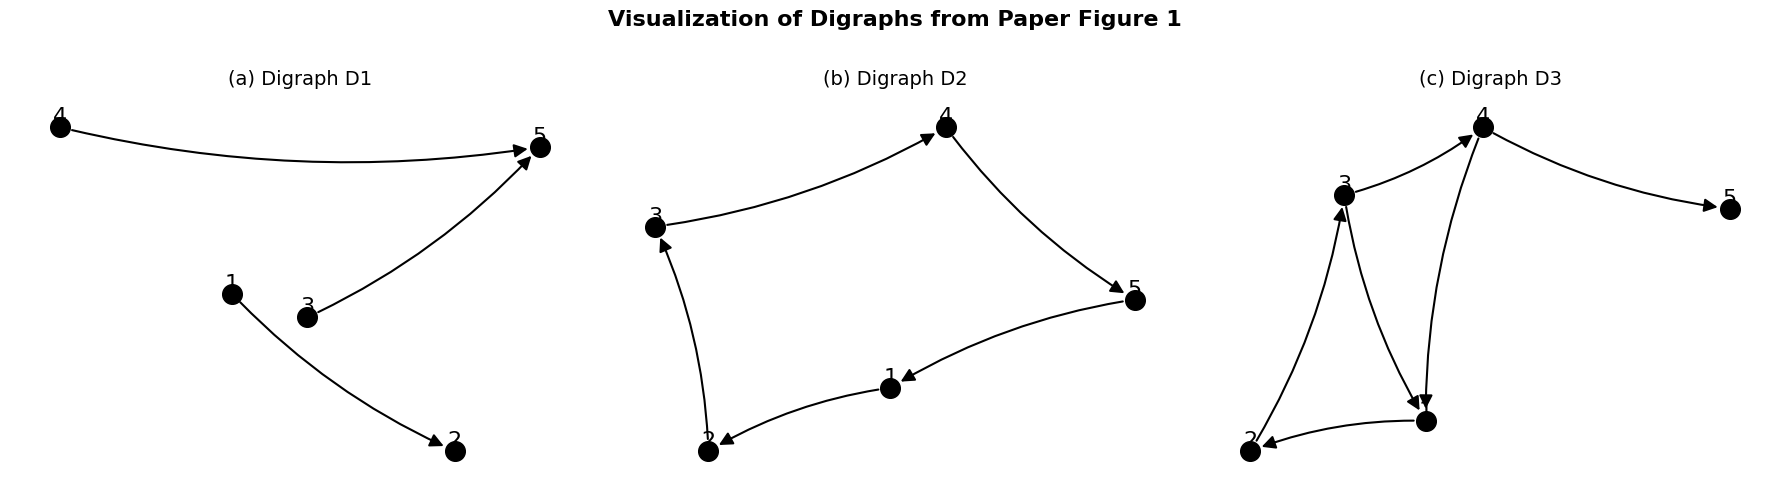

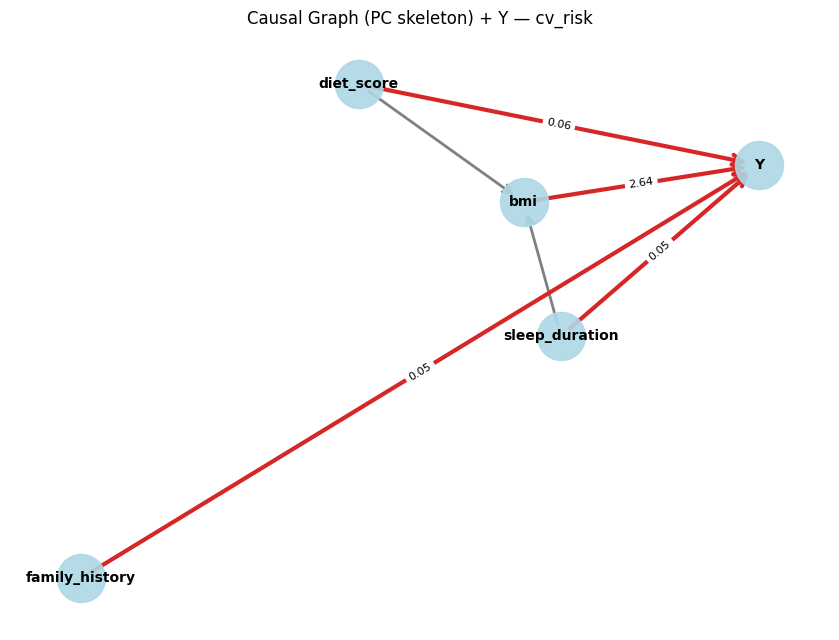

<Figure size 1200x500 with 0 Axes>

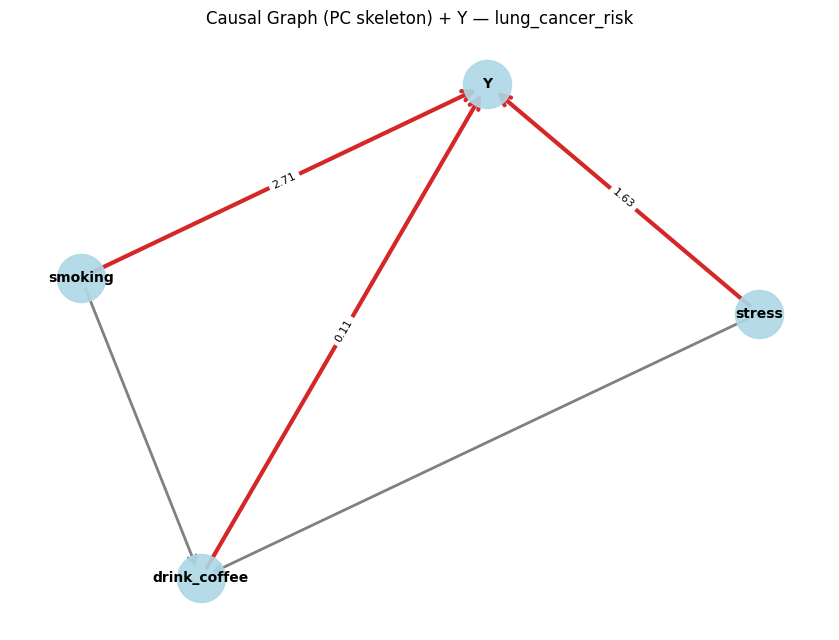

<Figure size 1200x500 with 0 Axes>

In [5]:
# Causal Graph (PC) + Myerson Value on Real Data + Paper Example
# - Causal graph from PC (CPDAG skeleton) -> used as Myerson digraph (directed)
# - Coalition worth v(S): RandomForest R^2 via k-fold CV (non-additive)
# - Exact Shapley for small n; permutation fallback for larger n
# - Memoization for speed
import math
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from typing import Dict, Set, FrozenSet, List, Callable, Optional
from functools import lru_cache
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression

try:
    from causallearn.search.ConstraintBased.PC import pc
except Exception as e:
    raise ImportError("Please install causallearn: pip install causallearn\n" + str(e))

RNG = np.random.default_rng(42)

class TUGame:
    def __init__(self, players: List[str], v_func: Callable[[FrozenSet[str]], float]):
        self.players = players
        self.N = frozenset(players)
        self._v = v_func

    @lru_cache(maxsize=None)
    def worth_frozen(self, S: FrozenSet[str]) -> float:
        return 0.0 if not S else self._v(S)

    def worth(self, S: Set[str]) -> float:
        return self.worth_frozen(frozenset(S))

    def shapley_value(self) -> Dict[str, float]:
        n = len(self.players)
        phi = {p: 0.0 for p in self.players}
        denom = math.factorial(n)
        for player in self.players:
            others = [p for p in self.players if p != player]
            for r in range(n):
                w = (math.factorial(r) * math.factorial(n - r - 1)) / denom
                for S_tuple in combinations(others, r):
                    S = set(S_tuple)
                    phi[player] += w * (self.worth(S | {player}) - self.worth(S))
        return phi

class DigraphGame(TUGame):
    def __init__(self, players: List[str], v_func: Callable[[FrozenSet[str]], float], digraph: nx.DiGraph):
        super().__init__(players, v_func)
        self.D = digraph

    @lru_cache(maxsize=None)
    def v_restricted_frozen(self, S: FrozenSet[str]) -> float:
        if not S: return 0.0
        subgraph = self.D.subgraph(S)
        return sum(self.worth_frozen(frozenset(scc)) for scc in nx.strongly_connected_components(subgraph))

    def v_restricted(self, S: Set[str]) -> float:
        return self.v_restricted_frozen(frozenset(S))

    def myerson_value(self) -> Dict[str, float]:
        restricted = lambda s: self.v_restricted_frozen(frozenset(s))
        return TUGame(self.players, restricted).shapley_value()

def print_digraph(D: nx.DiGraph, name: str):
    print(f"\n{name}: nodes={len(D.nodes)}, edges={len(D.edges)}")
    for u in sorted(D.nodes):
        print(f"  {u} -> {sorted(D.successors(u))}")

def draw_digraph(D: nx.DiGraph, name: str, layout: str = "spring"):
    plt.figure(figsize=(5.0, 4.0))
    pos = nx.spring_layout(D, seed=42) if layout=="spring" else nx.circular_layout(D)
    nx.draw_networkx_nodes(D, pos, node_size=700)
    nx.draw_networkx_labels(D, pos, font_size=11)
    nx.draw_networkx_edges(D, pos, arrows=True, arrowstyle='-|>', arrowsize=14, width=1.5)
    plt.axis("off"); plt.title(name)
    out = f"{name.replace(' ', '_')}.png"
    plt.tight_layout(); plt.savefig(out, dpi=180); plt.close()
    print(f"Saved {out}")

def reproduce_paper_example():
    """
    Reproduces Example 1 using the EXACT graphs from the paper's Figure 1 and visualizes them.
    """
    print("="*70 + "\nREPRODUCING PAPER EXAMPLE 1 (Section 3.2)\n" + "="*70)
    players = ['1', '2', '3', '4', '5']
    def v_quadratic(S: FrozenSet[str]) -> float: return len(S) ** 2

    # Graph D1: Exact edges from Figure 1(a)
    D1 = nx.DiGraph(); D1.add_nodes_from(players)
    D1.add_edges_from([('1', '2'), ('3', '5'), ('4', '5')])

    # Graph D2: Exact edges from Figure 1(b)
    D2 = nx.DiGraph(); D2.add_nodes_from(players)
    D2.add_edges_from([('1', '2'), ('2', '3'), ('3', '4'), ('4', '5'), ('5', '1')])

    # Graph D3: Exact edges from Figure 1(c)
    D3 = nx.DiGraph(); D3.add_nodes_from(players)
    D3.add_edges_from([('1', '2'), ('3', '1'), ('2', '3'), ('3', '4'),('4','1'), ('4', '5')])

    graphs = {'(a) Digraph D1': D1, '(b) Digraph D2': D2, '(c) Digraph D3': D3}

    print("\n--- Calculations ---")
    game1 = DigraphGame(players, v_quadratic, D1); mu1 = game1.myerson_value()
    game2 = DigraphGame(players, v_quadratic, D2); mu2 = game2.myerson_value()
    game3 = DigraphGame(players, v_quadratic, D3); mu3 = game3.myerson_value()

    print(f"D1 Calculated Result: {mu1}")
    print(f"D2 Calculated Result: {mu2}")
    print(f"D3 Calculated Result (from diagram): {mu3}")
    print(f"D3 Paper's Stated Result (from text): {{'1': 4.5, '2': 4.5, '3': 4.5, '4': 2.5, '5': 1.0}}")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Visualization of Digraphs from Paper Figure 1', fontsize=16, fontweight='bold')

    for ax, (title, G) in zip(axes, graphs.items()):
        pos = nx.spring_layout(G, seed=42, k=0.9)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color='black', node_size=200)
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color='black', arrowsize=20, width=1.5,
                               connectionstyle='arc3,rad=0.1')
        nx.draw_networkx_labels(G, pos, ax=ax, font_color='black', font_size=16, verticalalignment='bottom')
        ax.set_title(title, fontsize=14)
        ax.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig('paper_digraphs_visualization.png')
    print("\nSaved visualization to 'paper_digraphs_visualization.png'")


def create_interactional_v_func(X: pd.DataFrame, y: np.ndarray, model_template, k: int = 3):
    memo = {}
    X_vals = X.values
    cols = list(X.columns)
    k = max(2, min(k, len(y)))  # guard

    def v(S: FrozenSet[str]) -> float:
        if not S: return 0.0
        if S in memo: return memo[S]
        idx = [cols.index(c) for c in S]
        X_sub = X_vals[:, idx]
        kf = KFold(n_splits=k, shuffle=True, random_state=42)
        scores = []
        for tr, te in kf.split(X_sub):
            m = clone(model_template)
            m.fit(X_sub[tr], y[tr])
            yhat = m.predict(X_sub[te])
            scores.append(r2_score(y[te], yhat))
        memo[S] = max(0.0, float(np.mean(scores)))
        return memo[S]
    return v

def pc_discover_digraph(X: pd.DataFrame, alpha: float = 0.1) -> nx.DiGraph:
    """
    Run PC on standardized features and return a directed DiGraph:
      - Oriented edges i->j kept as directed
      - Undirected CPDAG pairs i-j are added both ways (i->j and j->i)
    """
    print(f"Running PC (alpha={alpha}) on {X.shape[1]} features ...")
    res = pc(X.values, alpha=alpha, show_progress=False)
    cpdag = res.G.graph
    names = list(X.columns)

    G = nx.DiGraph()
    G.add_nodes_from(names)
    n = len(names)
    for i in range(n):
        for j in range(n):
            if i == j: continue
            # directed i->j encoded as (-1, +1)
            if cpdag[i, j] == -1 and cpdag[j, i] == 1:
                G.add_edge(names[i], names[j])
            # undirected i-j ⇒ add both directions exactly once
            elif cpdag[i, j] == -1 and cpdag[j, i] == -1 and i < j:
                G.add_edge(names[i], names[j])
                G.add_edge(names[j], names[i])
    print(f"PC skeleton: nodes={G.number_of_nodes()}, edges={G.number_of_edges()}")
    return G

def plot_causal_graph_with_target(G_features: nx.DiGraph, X: pd.DataFrame, y: pd.Series, title="Causal Graph + Y"):
    """Augment feature graph with Y edges using |beta_f| from linear regression Y~X."""
    G = nx.DiGraph()
    G.add_nodes_from(G_features.nodes())
    G.add_edges_from(G_features.edges())
    lrY = LinearRegression().fit(X.values, y.values)
    betas = dict(zip(X.columns, np.abs(lrY.coef_)))
    G.add_node("Y")
    for f, w in betas.items():
        if w > 1e-12:
            G.add_edge(f, "Y", weight=float(w))
    plt.figure(figsize=(8.5, 6.5))
    pos = nx.spring_layout(G, seed=42, k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edgelist=[e for e in G.edges() if e[1]!="Y"],
                           edge_color='gray', arrows=True, arrowsize=15, width=2, arrowstyle='->')
    nx.draw_networkx_edges(G, pos, edgelist=[e for e in G.edges() if e[1]=="Y"],
                           edge_color='tab:red', arrows=True, arrowsize=18, width=3, arrowstyle='->')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    elabs = {(u,v): f"{G[u][v].get('weight',0):.2f}" for (u,v) in G.edges() if v=="Y"}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=elabs, font_size=8)
    plt.title(title); plt.axis('off'); plt.tight_layout()
    return plt.gcf()

def shapley_permutation_sampling(players: List[str],
                                 worth_fn: Callable[[FrozenSet[str]], float],
                                 m: int = 4096, seed: int = 42) -> Dict[str, float]:
    rng = np.random.default_rng(seed)
    n = len(players)
    phi = {p: 0.0 for p in players}
    arr = np.array(players)
    empty = frozenset()
    base = worth_fn(empty)
    for _ in range(m):
        perm = arr[rng.permutation(n)]
        S = empty; prev = base
        for p in perm:
            S2 = frozenset(set(S) | {p})
            val = worth_fn(S2)
            phi[p] += (val - prev)
            S, prev = S2, val
    for p in phi: phi[p] /= m
    return phi

def analyze_dataset_with_pc(csv_paths: List[str], dataset_name: str, target_hint: Optional[str] = None,
                            alpha_pc: float = 0.1,
                            corr_threshold_unused: float = 0.25,  # not used anymore
                            n_estimators: int = 120, max_depth: Optional[int] = None,
                            cv_k: int = 3, m_permutations: int = 4096, exact_cutoff: int = 12):
    print("\n" + "="*78)
    print(f"DATASET: {dataset_name}")
    print("="*78)

    # Load first path that exists
    df = None
    for p in csv_paths:
        try:
            df = pd.read_csv(p); print(f"Loaded: {p}"); break
        except Exception: continue
    if df is None:
        print(f"Warning: Skipping {dataset_name}: none of these paths exist: {csv_paths}")
        return

    # Drop unnamed; pick target
    df = df[[c for c in df.columns if not c.lower().startswith('unnamed')]]
    if target_hint and target_hint in df.columns:
        target_col = target_hint
    else:
        commons = ['target','risk','outcome','class','label','TenYearCHD','cv_risk','lung_cancer_risk']
        target_col = next((t for t in commons if t in df.columns), df.columns[-1])

    y = pd.to_numeric(df[target_col], errors='coerce').fillna(df[target_col].median())
    X = df.drop(columns=[target_col]).select_dtypes(include=[np.number])
    if X.shape[1] == 0:
        print("No numeric features found; skipping."); return
    X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median(numeric_only=True))

    # Scale
    scaler = StandardScaler()
    Xs = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

    D = pc_discover_digraph(Xs, alpha=alpha_pc)
    print_digraph(D, f"causal_digraph_{dataset_name}")
    fig = plot_causal_graph_with_target(D, Xs, y, title=f"Causal Graph (PC skeleton) + Y — {dataset_name}")
    fig.savefig(f"causal_graph_{dataset_name}.png", dpi=150, bbox_inches='tight')
    print(f"Saved causal_graph_{dataset_name}2.png")

    rf_template = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                        random_state=42, n_jobs=-1)
    v_func = create_interactional_v_func(Xs, y.values, rf_template, k=cv_k)

    players = list(Xs.columns)
    temp_game = DigraphGame(players, v_func, D)
    if len(players) <= exact_cutoff:
        myerson = temp_game.myerson_value()
        shapley = TUGame(players, v_func).shapley_value()
        mode = "exact"
    else:
        myerson = shapley_permutation_sampling(players, lambda S: temp_game.v_restricted_frozen(S),
                                               m=m_permutations, seed=42)
        shapley = shapley_permutation_sampling(players, lambda S: v_func(S),
                                               m=m_permutations, seed=43)
        mode = f"MC ({m_permutations} perms)"

    res = pd.DataFrame({
        'Feature': players,
        'Myerson_Value': [myerson[p] for p in players],
        'Shapley_Value': [shapley[p] for p in players],
    }).set_index('Feature')
    res['Difference'] = res['Myerson_Value'] - res['Shapley_Value']
    res_disp = res.sort_values('Myerson_Value', ascending=False)

    print(f"\nTop features by Myerson value ({mode}):")
    print(res_disp.head(15).to_string(float_format=lambda x: f"{x:0.4f}"))

    out_csv = f"myerson_results_{dataset_name}.csv"
    res_disp.to_csv(out_csv); print(f"Saved results to {out_csv}")

    plt.figure(figsize=(max(12, 0.6*len(res_disp)), 5))
    res_disp[['Myerson_Value','Shapley_Value']].plot(kind='bar')
    plt.title(f"Myerson vs Shapley — {dataset_name} [{mode}]")
    plt.xlabel("Feature"); plt.ylabel("Value")
    plt.tight_layout(); out_png = f"myerson_vs_shapley_{dataset_name}2.png"
    plt.savefig(out_png, dpi=180); plt.close(); print(f"Saved {out_png}")

    plt.figure(figsize=(6.8, 5.2))
    pos = nx.spring_layout(D, seed=42)
    node_vals = [res.loc[n, 'Myerson_Value'] for n in D.nodes()]
    nx.draw(D, pos, with_labels=True, node_color=node_vals, cmap=plt.cm.viridis,
            node_size=1600, font_size=10, font_weight='bold',
            arrows=True, arrowstyle='-|>', arrowsize=14)
    plt.title(f"Communication Digraph (PC skeleton) — {dataset_name}")
    plt.tight_layout(); out_graph = f"digraph_{dataset_name}2.png"
    plt.savefig(out_graph, dpi=180); plt.close(); print(f"Saved {out_graph}")

def run_real_datasets():
    analyze_dataset_with_pc(
        csv_paths=["cv_risk.csv", "../../datasets/cv_risk.csv"],
        dataset_name="cv_risk",
        target_hint="cv_risk",
        alpha_pc=0.1,
        n_estimators=120, max_depth=None, cv_k=3, m_permutations=4096, exact_cutoff=12
    )
    analyze_dataset_with_pc(
        csv_paths=["lung_cancer_risk.csv", "../../datasets/lung_cancer_risk.csv"],
        dataset_name="lung_cancer_risk",
        target_hint="lung_cancer_risk",
        alpha_pc=0.1,
        n_estimators=120, max_depth=None, cv_k=3, m_permutations=4096, exact_cutoff=12
    )

def main():
    reproduce_paper_example()
    print("\n" + "#"*70 + "\n# PART 2: APPLY TO REAL DATASETS (PC graph → Myerson)\n" + "#"*70)
    run_real_datasets()

if __name__ == "__main__":
    main()